# Detencion Terremotos

Lucho Sep | 2021 <br>
Oxford Comma by Vampire Weekend


### Descripcion: <br>

Este dataset contiene información sobre terremotos, con un total de 2719 registros y cuatro variables numéricas que describen la ubicación geográfica, la profundidad y la magnitud de cada evento sísmico.

- Latitude (Latitud): indica la posición norte-sur del epicentro del terremoto, expresada en grados geográficos.

- Longitude (Longitud): indica la posición este-oeste del epicentro, expresada en grados geográficos.

- Depth (Profundidad): representa la profundidad a la que se originó el terremoto, generalmente medida en kilómetros.

- Magnitude (Magnitud): mide el tamaño del terremoto y la energía liberada durante el evento sísmico.

### Import Packages | Libraries

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import joblib
import os, warnings

warnings.filterwarnings("ignore")
from sklearn.model_selection import train_test_split
import pickle
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (mean_absolute_error,mean_squared_error,r2_score, accuracy_score,precision_score,recall_score,f1_score,
                            ConfusionMatrixDisplay,classification_report)
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


### Import Dataset

In [2]:
df = pd.read_csv(r"earthquake_data.csv")
df_raw = df.copy()
df.head()

,Latitude,Longitude,Depth,Magnitude
0,29.06,77.42,5.0,2.5
1,19.93,72.92,5.0,2.4
2,31.50,74.37,33.0,3.4
3,28.34,76.23,5.0,3.1
4,27.09,89.97,10.0,2.1


In [3]:
df.shape

(2719, 4)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2719 entries, 0 to 2718
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Latitude   2719 non-null   float64
 1   Longitude  2719 non-null   float64
 2   Depth      2719 non-null   float64
 3   Magnitude  2719 non-null   float64
dtypes: float64(4)
memory usage: 85.1 KB


In [5]:
df.isna().sum()

Latitude     0
Longitude    0
Depth        0
Magnitude    0
dtype: int64

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Latitude,2719.0,29.939433,7.361564,0.12,25.70,31.21,36.390,40.00
Longitude,2719.0,80.905638,10.139075,60.30,71.81,76.61,92.515,99.96
Depth,2719.0,53.400478,68.239737,0.80,10.00,15.00,82.000,471.00
Magnitude,2719.0,3.772196,0.768076,1.50,3.20,3.90,4.300,7.00


### Analisis Exploratorio Datos (EDA)

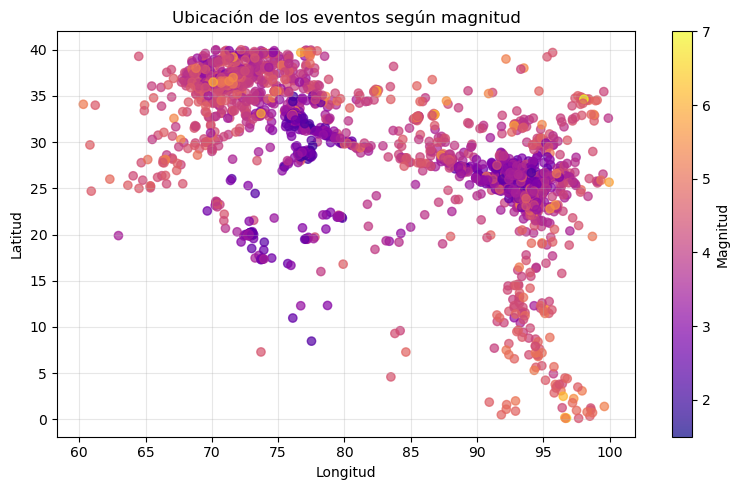

In [7]:
plt.figure(figsize=(8, 5))

plt.scatter( df["Longitude"],df["Latitude"],c=df["Magnitude"],cmap="plasma",alpha=0.7)

plt.colorbar(label="Magnitud")
plt.xlabel("Longitud")
plt.ylabel("Latitud")
plt.title("Ubicación de los eventos según magnitud")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show() 

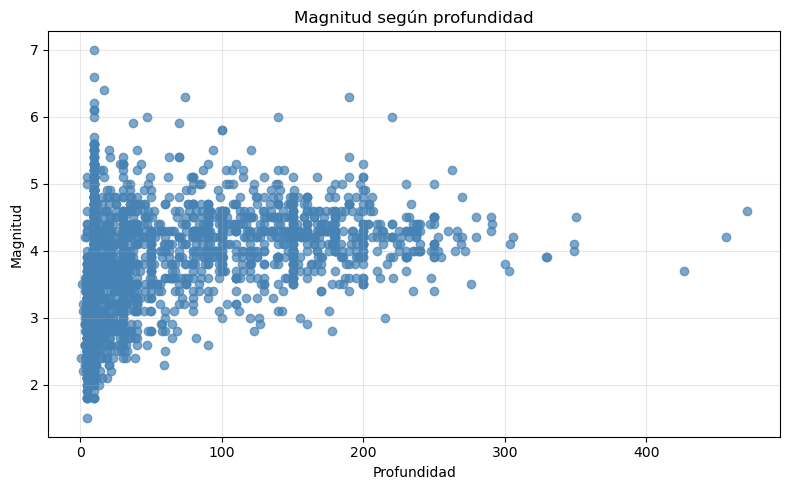

In [8]:
plt.figure(figsize=(8, 5))

plt.scatter(df["Depth"],df["Magnitude"],color="steelblue",alpha=0.7)

plt.xlabel("Profundidad")
plt.ylabel("Magnitud")
plt.title("Magnitud según profundidad")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

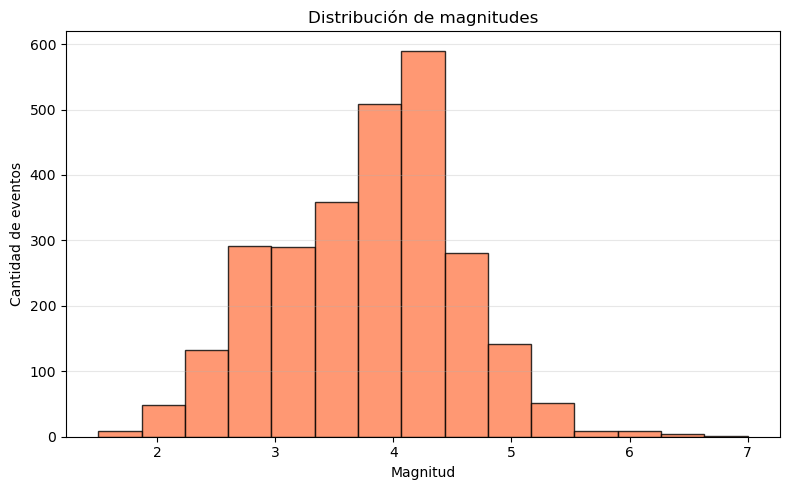

In [9]:
plt.figure(figsize=(8, 5))

plt.hist(df["Magnitude"],bins=15,color="coral",edgecolor="black",alpha=0.8)

plt.xlabel("Magnitud")
plt.ylabel("Cantidad de eventos")
plt.title("Distribución de magnitudes")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Preparacion Datos & Desarrollo

#### Regresion (Prediccion)

In [10]:
X = df[["Latitude", "Longitude", "Depth"]]


y = df["Magnitude"]

In [11]:
X_train, X_test, y_train, y_test = train_test_split( X,y,test_size=0.2,random_state=42)

print("\nDatos de entrenamiento:", len(X_train))
print("Datos de prueba:", len(X_test))


Datos de entrenamiento: 2175
Datos de prueba: 544


In [12]:
modelos = {
    "Random Forest": RandomForestRegressor(n_estimators=200,random_state=42,n_jobs=-1),
    "Regresión Lineal": LinearRegression()
}

resultados = []
modelos_entrenados = {}
predicciones = {}

In [13]:
for nombre, modelo in modelos.items():

    modelo.fit(X_train, y_train)

    # Predicciones sobre datos no usados en el entrenamiento
    y_pred = modelo.predict(X_test)

    # Calcular métricas de regresión
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    resultados.append({
        "Modelo": nombre,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    modelos_entrenados[nombre] = modelo
    predicciones[nombre] = y_pred

    print(f"\n===== {nombre} =====")
    print(f"MAE:  {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"R²:   {r2:.4f}")


===== Random Forest =====
MAE:  0.4193
RMSE: 0.5548
R²:   0.4767

===== Regresión Lineal =====
MAE:  0.5815
RMSE: 0.7447
R²:   0.0569


In [14]:
df_resultados = pd.DataFrame(resultados).set_index("Modelo")

print("\n===== COMPARACIÓN DE MODELOS =====")
print(df_resultados.round(4))

# Elegir el modelo con menor RMSE
mejor_nombre = df_resultados["RMSE"].idxmin()
mejor_modelo = modelos_entrenados[mejor_nombre]

print("\nMejor modelo:", mejor_nombre)
print("RMSE:", round(df_resultados.loc[mejor_nombre, "RMSE"], 4))
print("MAE:", round(df_resultados.loc[mejor_nombre, "MAE"], 4))
print("R²:", round(df_resultados.loc[mejor_nombre, "R2"], 4))


===== COMPARACIÓN DE MODELOS =====
                     MAE    RMSE      R2
Modelo                                  
Random Forest     0.4193  0.5548  0.4767
Regresión Lineal  0.5815  0.7447  0.0569

Mejor modelo: Random Forest
RMSE: 0.5548
MAE: 0.4193
R²: 0.4767


In [15]:
joblib.dump(mejor_modelo, "mejor_modelo_sismos.joblib")

print("\nModelo guardado como mejor_modelo_sismos.joblib")


Modelo guardado como mejor_modelo_sismos.joblib


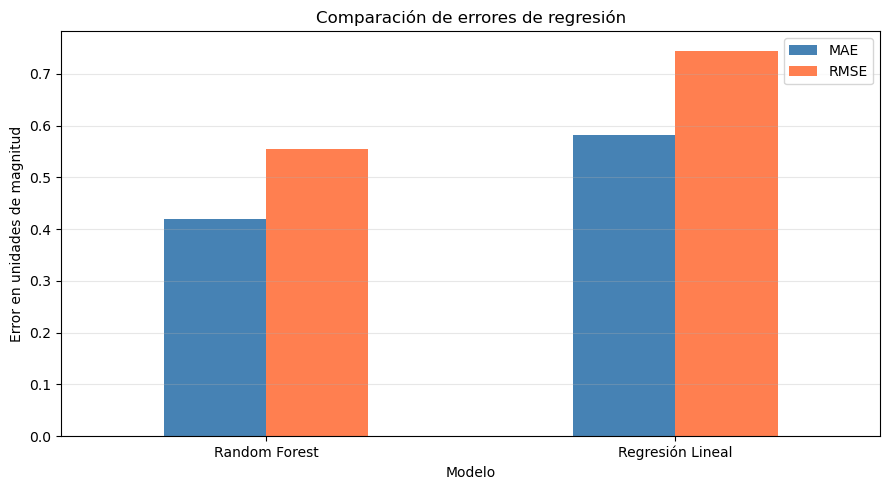

In [16]:
ax = df_resultados[["MAE", "RMSE"]].plot(kind="bar",figsize=(9, 5),color=["steelblue", "coral"],rot=0)

ax.set_title("Comparación de errores de regresión")
ax.set_ylabel("Error en unidades de magnitud")
ax.set_xlabel("Modelo")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

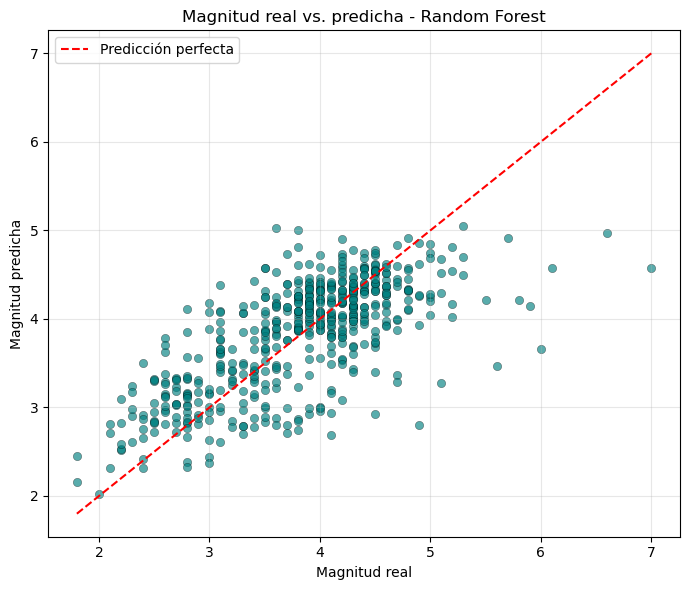

In [17]:
y_pred_mejor = predicciones[mejor_nombre]

plt.figure(figsize=(7, 6))

plt.scatter( y_test,y_pred_mejor,alpha=0.65,color="teal",edgecolors="black",linewidths=0.3)

# Diagonal de predicción perfecta
minimo = min(y_test.min(), y_pred_mejor.min())
maximo = max(y_test.max(), y_pred_mejor.max())

plt.plot(
    [minimo, maximo],
    [minimo, maximo],
    "r--",
    label="Predicción perfecta"
)

plt.xlabel("Magnitud real")
plt.ylabel("Magnitud predicha")
plt.title(f"Magnitud real vs. predicha - {mejor_nombre}")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Verificacion Modelo

In [18]:
modelo = joblib.load("mejor_modelo_sismos.joblib")

# Reemplazar por valores de entrada reales
nuevo_sismo = pd.DataFrame([{
    "Latitude": -34.60,
    "Longitude": -58.38,
    "Depth": 25.0
}])

magnitud_predicha = modelo.predict(nuevo_sismo)

print("Magnitud predicha:", round(magnitud_predicha[0], 2))

Magnitud predicha: 4.08


#### Clasificacion

In [19]:
columnas = ["Latitude", "Longitude", "Depth", "Magnitude"]
df = df[columnas].copy()

for col in columnas:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.replace([np.inf, -np.inf], np.nan).dropna()

In [20]:
df["Magnitude_Class"] = pd.cut(df["Magnitude"],bins=[-np.inf, 4.0, 6.0, np.inf],labels=["Baja", "Moderada", "Alta"],right=False)

print("Cantidad por categoría:")
print(df["Magnitude_Class"].value_counts())

# Variables predictoras
X = df[["Latitude", "Longitude", "Depth"]]

# Categoría que queremos predecir
y = df["Magnitude_Class"]

Cantidad por categoría:
Magnitude_Class
Baja        1485
Moderada    1222
Alta          12
Name: count, dtype: int64


In [21]:
conteos = y.value_counts()

if (conteos < 2).any():
    raise ValueError(
        "Hay categorías con menos de 2 registros. "
        "Revisá los límites de magnitud antes de usar stratify."
    )

X_train, X_test, y_train, y_test = train_test_split( X,y,test_size=0.2,random_state=42,stratify=y)

In [22]:
modelos = {
    "Random Forest": RandomForestClassifier(n_estimators=200,random_state=42,class_weight="balanced"),
    "Regresión Logística": make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000,class_weight="balanced"))
}

resultados = []
modelos_entrenados = {}
predicciones = {}

In [23]:
for nombre, modelo in modelos.items():

    modelo.fit(X_train, y_train)
    y_pred = modelo.predict(X_test)

    resultados.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(  y_test, y_pred,average="weighted",zero_division=0),
        "Recall": recall_score(y_test, y_pred,average="weighted",zero_division=0),
        "F1-score": f1_score( y_test, y_pred,average="weighted",zero_division=0)
    })

    modelos_entrenados[nombre] = modelo
    predicciones[nombre] = y_pred

    print(f"\n===== {nombre} =====")
    print(classification_report(
        y_test, y_pred, zero_division=0
    ))


===== Random Forest =====
              precision    recall  f1-score   support

        Alta       0.00      0.00      0.00         2
        Baja       0.79      0.75      0.77       297
    Moderada       0.71      0.76      0.73       245

    accuracy                           0.75       544
   macro avg       0.50      0.50      0.50       544
weighted avg       0.75      0.75      0.75       544


===== Regresión Logística =====
              precision    recall  f1-score   support

        Alta       0.01      0.50      0.02         2
        Baja       0.66      0.71      0.69       297
    Moderada       0.72      0.37      0.49       245

    accuracy                           0.56       544
   macro avg       0.46      0.53      0.40       544
weighted avg       0.68      0.56      0.59       544



In [24]:
df_resultados = pd.DataFrame(resultados).set_index("Modelo")

print("\nComparación de modelos:")
print(df_resultados.round(4))

# Seleccionar el mayor F1-score ponderado
mejor_nombre = df_resultados["F1-score"].idxmax()
mejor_modelo = modelos_entrenados[mejor_nombre]

print("\nMejor modelo:", mejor_nombre)
print("F1-score:", round(
    df_resultados.loc[mejor_nombre, "F1-score"], 4
))


Comparación de modelos:
                     Accuracy  Precision  Recall  F1-score
Modelo                                                    
Random Forest           0.750     0.7498   0.750    0.7492
Regresión Logística     0.557     0.6849   0.557    0.5937

Mejor modelo: Random Forest
F1-score: 0.7492


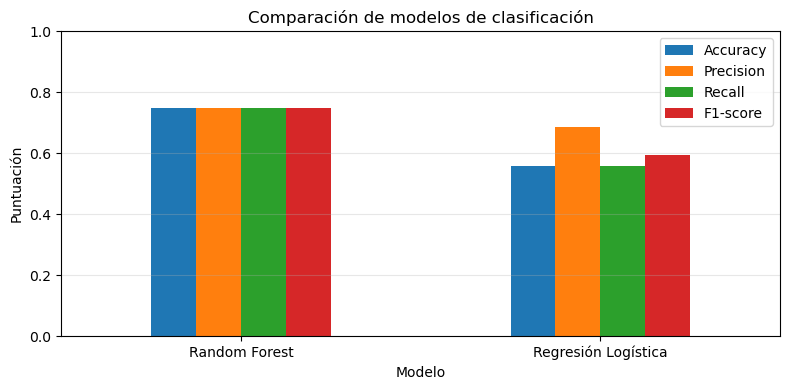

In [25]:
ax = df_resultados.plot(kind="bar",figsize=(8, 4),ylim=(0, 1),rot=0)

ax.set_title("Comparación de modelos de clasificación")
ax.set_ylabel("Puntuación")
ax.set_xlabel("Modelo")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

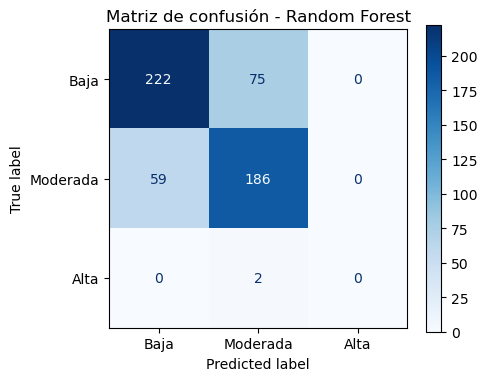

In [26]:
fig, ax = plt.subplots(figsize=(5, 4))

ConfusionMatrixDisplay.from_estimator(
    mejor_modelo,X_test,y_test,labels=["Baja", "Moderada", "Alta"],display_labels=["Baja", "Moderada", "Alta"],
    cmap="Blues",ax=ax)

ax.set_title(f"Matriz de confusión - {mejor_nombre}")

plt.tight_layout()
plt.show()

In [27]:
joblib.dump(mejor_modelo, "mejor_clasificador_sismos.joblib")

print("\nModelo guardado: mejor_clasificador_sismos.joblib")


Modelo guardado: mejor_clasificador_sismos.joblib


In [28]:
modelo = joblib.load("mejor_clasificador_sismos.joblib")

#  Predecir usando los datos de test existentes
y_pred = modelo.predict(X_test)

# Comparar predicciones con valores reales
resultados_test = X_test.copy()
resultados_test["Clase real"] = y_test.values
resultados_test["Clase predicha"] = y_pred
resultados_test["Correcto"] = (
    resultados_test["Clase real"].astype(str)
    == resultados_test["Clase predicha"].astype(str)
)

#  Mostrar resultados
print("===== EVALUACIÓN DEL MODELO GUARDADO =====")
print(resultados_test.head(15))

print("\nAccuracy en test:",
      round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred, zero_division=0))

===== EVALUACIÓN DEL MODELO GUARDADO =====
      Latitude  Longitude  Depth Clase real Clase predicha  Correcto
201      17.36      73.84    5.0       Baja           Baja      True
2454     37.60      75.50  100.0   Moderada       Moderada      True
9        37.96      72.39  160.0   Moderada       Moderada      True
1679     37.40      76.70   60.0   Moderada       Moderada      True
1742     35.80      70.90   78.0   Moderada       Moderada      True
2262     23.65      93.53   10.0       Baja           Baja      True
2320     25.70      91.00   10.0       Baja           Baja      True
53       36.52      71.31   70.0       Baja       Moderada     False
1404     30.13      95.08   10.0       Baja       Moderada     False
445      32.63      76.32   14.0       Baja           Baja      True
2290     36.90      71.90   40.0       Baja           Baja      True
1973     36.30      71.20  113.0   Moderada       Moderada      True
532      24.10      93.38   50.0       Baja           Baja  

In [29]:
nuevo_sismo = pd.DataFrame([{
    "Latitude": -34.60,
    "Longitude": -58.38,
    "Depth": 25.0
}])

prediccion = modelo.predict(nuevo_sismo)

print("Categoría predicha:", prediccion[0])

Categoría predicha: Moderada


### Conclusion

#### 1. Lo que muestra el EDA

- **Dataset limpio y chico:** 2.719 eventos, 4 variables numericas (latitud, longitud, profundidad y magnitud) y ningun dato faltante, por lo que no hizo falta imputar nada.
- **Distribucion de magnitudes:** tiene forma de campana, con media de ~3,77 y mediana de 3,9. La mayoria de los eventos se concentra entre 3 y 4,5, con un pico en 4-4,5. Los sismos grandes (>= 6) son muy pocos y el maximo es 7,0.
- **Ubicacion geografica:** los eventos no estan distribuidos al azar, sino que forman clusters claros: uno en el noroeste (lat 35-40, lon 67-75, zona Hindu Kush/Pamir), otro en el este (lat 22-28, lon 90-97) y una franja vertical que baja hacia el sur (lon ~92-98). En el mapa los eventos de mayor magnitud (colores calidos) se dispersan por varias zonas y no se concentran en una sola, lo que anticipa que la ubicacion por si sola no alcanza para determinar la magnitud.
- **Profundidad vs. magnitud:** la mayoria de los eventos son superficiales (mediana de 15 km) y ahi aparece todo el rango de magnitudes, incluidos los mas fuertes (>= 6, que ocurren a menos de ~70 km en su gran mayoria). Los eventos profundos (100-250 km) se agrupan en magnitudes medias (3,5-5) y casi no hay eventos chicos. Es una relacion **no lineal y con mucha dispersion**, no una recta clara, y hay algunos outliers de profundidad (> 400 km).

#### 2. Regresion (predecir la magnitud)

| Modelo | MAE | RMSE | R2 |
|---|---|---|---|
| Random Forest | 0,4193 | 0,5548 | 0,4767 |
| Regresion Lineal | 0,5815 | 0,7447 | 0,0569 |

- **Random Forest fue claramente mejor** y se guardo como modelo final: reduce el error en ~28% (MAE) y ~25% (RMSE) respecto a la regresion lineal.
- La **regresion lineal casi no explica nada** (R2 = 0,06), lo cual es consistente con el EDA: la relacion entre ubicacion/profundidad y magnitud no es lineal.
- Aun siendo el mejor, el Random Forest explica **menos de la mitad de la variabilidad** (R2 = 0,48) y se equivoca en promedio ~0,42 unidades de magnitud. Con solo latitud, longitud y profundidad el modelo sirve como estimacion orientativa, no como prediccion precisa.

#### 3. Clasificacion (Baja < 4 / Moderada 4-6 / Alta >= 6)

| Modelo | Accuracy | Precision | Recall | F1 (ponderado) |
|---|---|---|---|---|
| Random Forest | 0,750 | 0,7498 | 0,750 | 0,7492 |
| Regresion Logistica | 0,557 | 0,6849 | 0,557 | 0,5937 |

- **Random Forest fue el mejor** (accuracy 75%, F1 0,75). La regresion logistica rinde apenas por encima de predecir siempre la clase mayoritaria (Baja = ~55% de los datos), asi que no aporta mucho.
- Random Forest clasifica bien las clases **Baja** (F1 0,77) y **Moderada** (F1 0,73). La matriz de confusion muestra que los errores se dan entre clases vecinas (75 Baja predichas como Moderada y 59 Moderada predichas como Baja), y nunca confunde una Baja con una Alta.
- **Problema principal: la clase Alta.** Hay solo 12 eventos en todo el dataset (0,4%) y apenas 2 en el set de test. El Random Forest no acerto ninguno (precision, recall y F1 = 0). Por eso las metricas ponderadas (0,75) **ocultan** este fallo, y el macro avg (0,50) refleja mejor la realidad. Con tan pocos ejemplos tampoco se puede concluir que la clase Alta sea predecible o no.

#### 4. Limitaciones y recomendaciones

- **Desbalance de clases:** para detectar sismos de magnitud alta harian falta mas datos de esa categoria, tecnicas de remuestreo (SMOTE, oversampling) o reducir el umbral de la clase Alta. Para este objetivo conviene priorizar el recall de la clase Alta por encima de la accuracy global.
- **Pocas variables:** solo se usan 3 predictores. Agregar variables como fecha/hora, tipo de falla, zona tectonica o historial de sismicidad podria mejorar bastante el R2.
- **Validacion:** la division es aleatoria y los sismos de una misma zona son muy parecidos entre si (replicas, clusters), por lo que el test podria estar algo "contaminado" por eventos similares a los de entrenamiento. Una validacion cruzada o una division espacial/temporal daria una estimacion mas realista. Tambien queda pendiente ajustar hiperparametros.
- **Dominio de aplicacion:** el dataset cubre aproximadamente lat 0-40 y lon 60-100 (Asia central y del sur). Los ejemplos de verificacion con coordenadas de Buenos Aires (-34,60; -58,38) estan **fuera de ese rango**, asi que las predicciones (magnitud 4,08 y clase Moderada) son una extrapolacion sin respaldo y solo sirven para probar que el pipeline funciona.

**En sintesis:** los modelos basados en arboles (Random Forest) capturan relaciones no lineales que los modelos lineales no ven, y logran un desempeno razonable para clasificar sismos Bajos y Moderados (75% de accuracy). Sin embargo, con solo ubicacion y profundidad no es posible predecir magnitudes con precision ni detectar los sismos de magnitud alta, que son justamente los de mayor interes practico.